Wine Classification — Machine Learning Internship

This project implements a multiclass classification system using the Wine dataset from Scikit-learn.

The objective is to predict the class of a wine sample based on 13 chemical features using two machine learning algorithms:

Logistic Regression

Decision Tree Classifier

In [1]:
# Import the required libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine

# Load the Wine dataset
wine = load_wine(as_frame=True)

# Convert it into a DataFrame
df = wine.frame

# Display basic information
print("Dataset shape:", df.shape)

print("\nFeature names:")
print(wine.feature_names)

print("\nTarget classes:")
print(wine.target_names)

print("\nFirst five rows:")
display(df.head())

print("\nClass distribution:")
print(df["target"].value_counts().sort_index())

print("\nDataset information:")
df.info()

Dataset shape: (178, 14)

Feature names:
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']

Target classes:
['class_0' 'class_1' 'class_2']

First five rows:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0



Class distribution:
target
0    59
1    71
2    48
Name: count, dtype: int64

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 

Total missing values: 0
Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


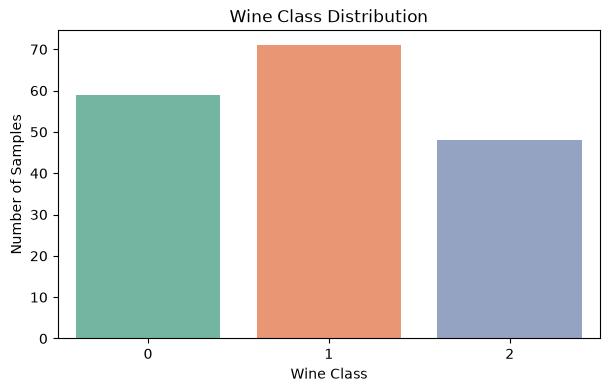

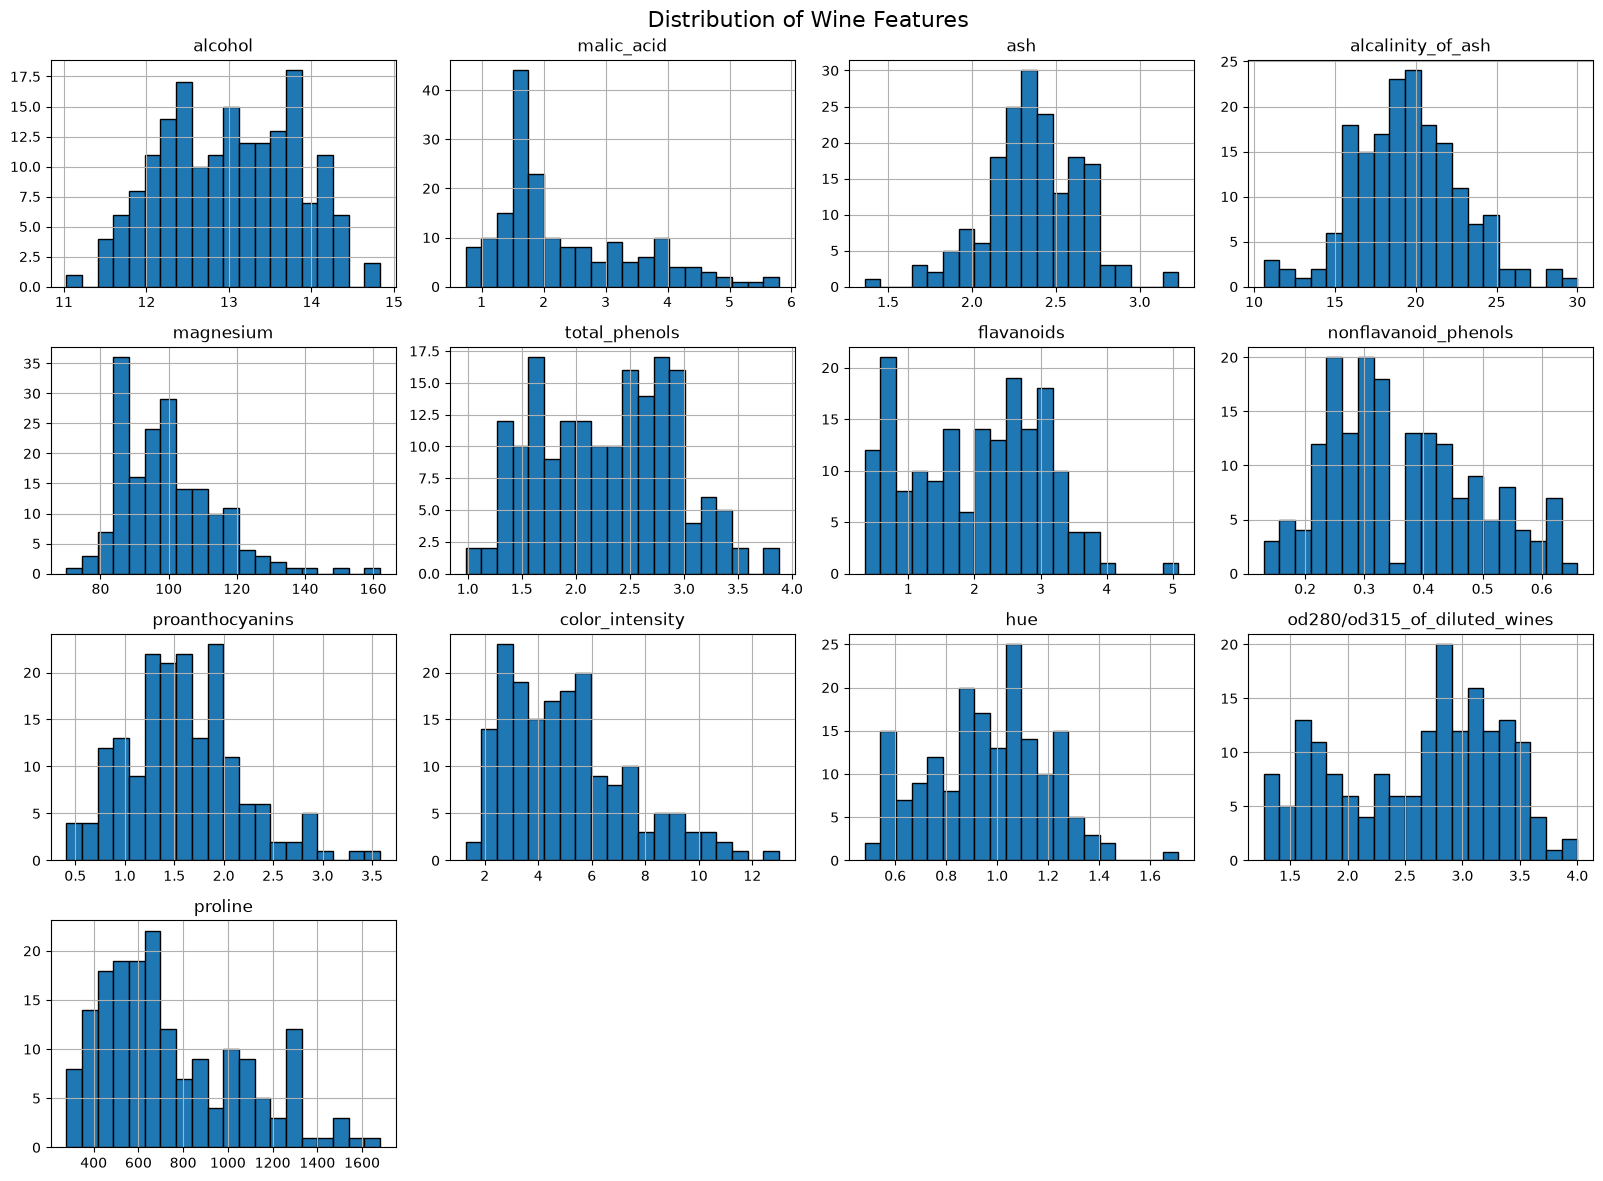

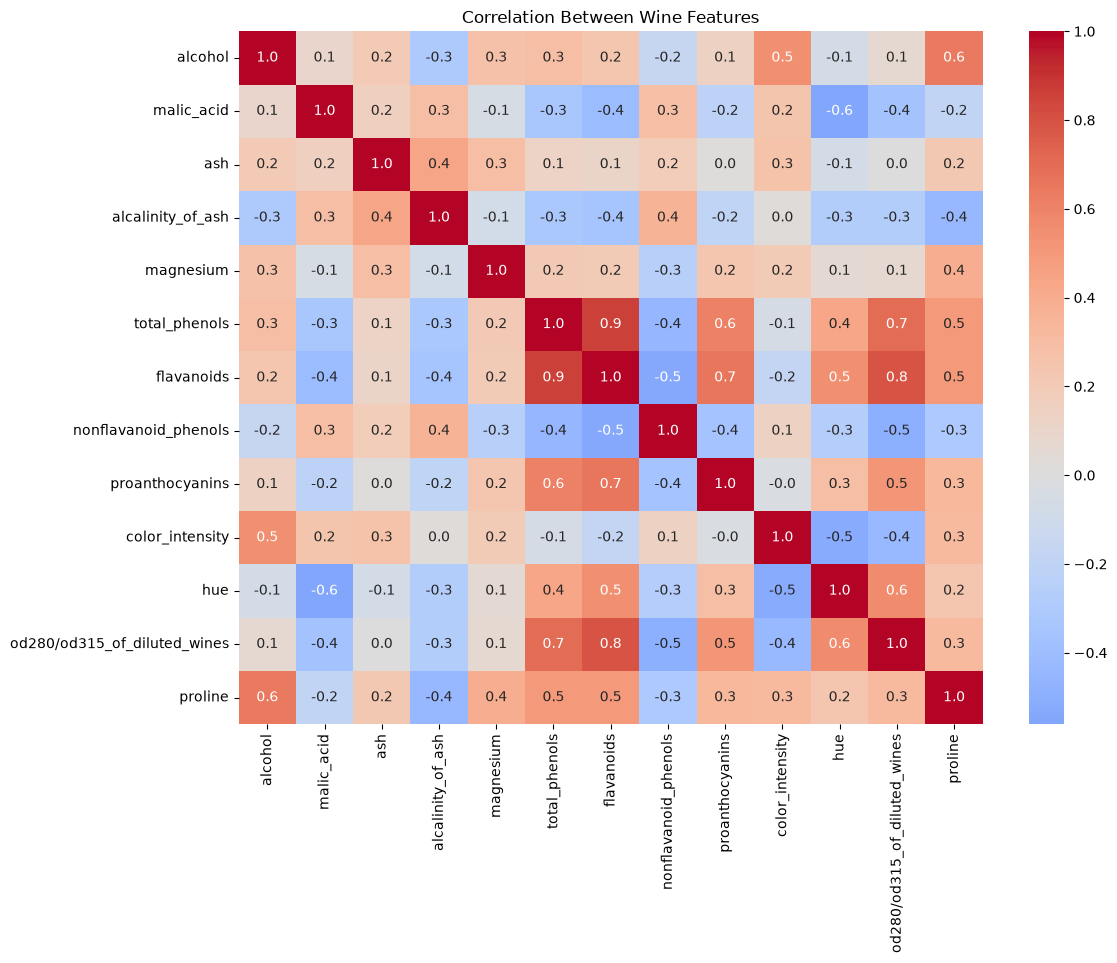

In [2]:
# 1. Check for missing values and duplicates
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

# 2. Statistical summary
display(df.describe().T)

# 3. Visualize class distribution
plt.figure(figsize=(7, 4))

sns.countplot(
    data=df,
    x="target",
    hue="target",
    palette="Set2",
    legend=False
)

plt.title("Wine Class Distribution")
plt.xlabel("Wine Class")
plt.ylabel("Number of Samples")
plt.show()

# 4. Visualize feature distributions
df.drop(columns="target").hist(
    figsize=(16, 12),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Wine Features", fontsize=16)
plt.tight_layout()
plt.show()

# 5. Correlation heatmap
plt.figure(figsize=(12, 9))

correlation = df.drop(columns="target").corr()

sns.heatmap(
    correlation,
    annot=True,
    fmt=".1f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Between Wine Features")
plt.show()

In [3]:
from sklearn.model_selection import train_test_split

# Separate input features and target
X = df.drop(columns="target")
y = df["target"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (178, 13)
Target shape: (178,)


In [4]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the resulting shapes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

# Check class distribution in both sets
print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())

Training features: (142, 13)
Testing features: (36, 13)

Training target: (142,)
Testing target: (36,)

Training class distribution:
target
0    47
1    57
2    38
Name: count, dtype: int64

Testing class distribution:
target
0    12
1    14
2    10
Name: count, dtype: int64


In [5]:
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Fit the scaler on training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Original training shape:", X_train.shape)
print("Scaled training shape:", X_train_scaled.shape)

print("\nOriginal testing shape:", X_test.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Original training shape: (142, 13)
Scaled training shape: (142, 13)

Original testing shape: (36, 13)
Scaled testing shape: (36, 13)


In [6]:
# Convert scaled training data back into a DataFrame
X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=X.columns
)

# Display means and standard deviations
print("Feature means after scaling:")
display(X_train_scaled_df.mean().round(3))

print("\nFeature standard deviations after scaling:")
display(X_train_scaled_df.std().round(3))

Feature means after scaling:


alcohol                         0.0
malic_acid                     -0.0
ash                             0.0
alcalinity_of_ash               0.0
magnesium                       0.0
total_phenols                  -0.0
flavanoids                      0.0
nonflavanoid_phenols           -0.0
proanthocyanins                -0.0
color_intensity                 0.0
hue                            -0.0
od280/od315_of_diluted_wines    0.0
proline                        -0.0
dtype: float64


Feature standard deviations after scaling:


alcohol                         1.004
malic_acid                      1.004
ash                             1.004
alcalinity_of_ash               1.004
magnesium                       1.004
total_phenols                   1.004
flavanoids                      1.004
nonflavanoid_phenols            1.004
proanthocyanins                 1.004
color_intensity                 1.004
hue                             1.004
od280/od315_of_diluted_wines    1.004
proline                         1.004
dtype: float64

In [7]:
from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [8]:
# Predict classes for the testing dataset
y_pred_logistic = logistic_model.predict(X_test_scaled)

# Predict class probabilities
y_proba_logistic = logistic_model.predict_proba(X_test_scaled)

print("First 10 actual labels:")
print(y_test.iloc[:10].values)

print("\nFirst 10 predicted labels:")
print(y_pred_logistic[:10])

print("\nFirst 5 probability predictions:")
print(y_proba_logistic[:5].round(3))

First 10 actual labels:
[0 2 0 1 1 0 0 1 1 2]

First 10 predicted labels:
[0 1 0 1 1 0 0 1 1 2]

First 5 probability predictions:
[[1.    0.    0.   ]
 [0.007 0.54  0.453]
 [0.992 0.008 0.   ]
 [0.29  0.707 0.003]
 [0.033 0.962 0.005]]


In [9]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred_logistic)

precision = precision_score(
    y_test,
    y_pred_logistic,
    average="weighted"
)

recall = recall_score(
    y_test,
    y_pred_logistic,
    average="weighted"
)

f1 = f1_score(
    y_test,
    y_pred_logistic,
    average="weighted"
)

# Display results
print("LOGISTIC REGRESSION - EVALUATION")
print("=" * 40)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_logistic))

LOGISTIC REGRESSION - EVALUATION
Accuracy:  0.9722
Precision: 0.9741
Recall:    0.9722
F1-score:  0.9720

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.93      1.00      0.97        14
           2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



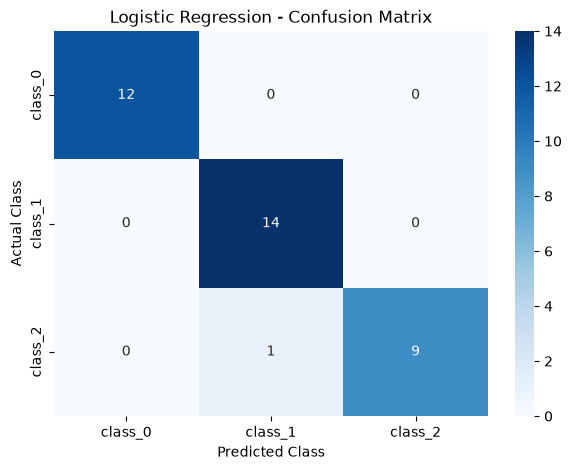

In [10]:
from sklearn.metrics import confusion_matrix

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred_logistic)

# Visualize confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=wine.target_names,
    yticklabels=wine.target_names
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

In [11]:
from sklearn.tree import DecisionTreeClassifier

# Create the Decision Tree model
tree_model = DecisionTreeClassifier(
    random_state=42
)

# Train using original, unscaled training data
tree_model.fit(X_train, y_train)

print("Decision Tree training completed!")

Decision Tree training completed!


In [12]:
# Predict classes on the test dataset
y_pred_tree = tree_model.predict(X_test)

print("First 10 actual labels:")
print(y_test.iloc[:10].values)

print("\nFirst 10 predicted labels:")
print(y_pred_tree[:10])

First 10 actual labels:
[0 2 0 1 1 0 0 1 1 2]

First 10 predicted labels:
[0 1 0 1 1 0 0 1 1 2]


In [13]:
# Calculate metrics
tree_accuracy = accuracy_score(y_test, y_pred_tree)

tree_precision = precision_score(
    y_test, y_pred_tree, average="weighted"
)

tree_recall = recall_score(
    y_test, y_pred_tree, average="weighted"
)

tree_f1 = f1_score(
    y_test, y_pred_tree, average="weighted"
)

print("DECISION TREE - EVALUATION")
print("=" * 40)

print(f"Accuracy:  {tree_accuracy:.4f}")
print(f"Precision: {tree_precision:.4f}")
print(f"Recall:    {tree_recall:.4f}")
print(f"F1-score:  {tree_f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tree))

DECISION TREE - EVALUATION
Accuracy:  0.9444
Precision: 0.9514
Recall:    0.9444
F1-score:  0.9450

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.92      0.96        12
           1       0.88      1.00      0.93        14
           2       1.00      0.90      0.95        10

    accuracy                           0.94        36
   macro avg       0.96      0.94      0.95        36
weighted avg       0.95      0.94      0.94        36



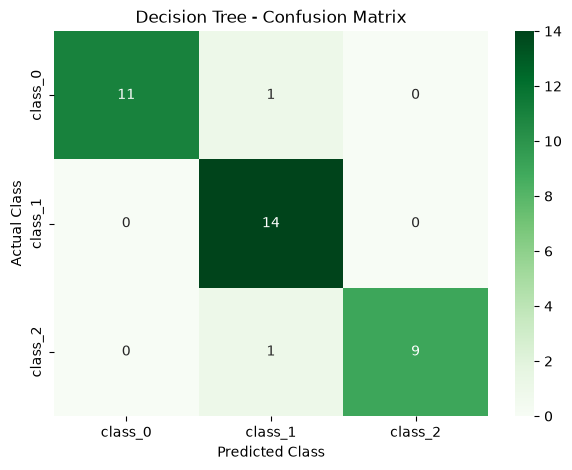

In [14]:
cm_tree = confusion_matrix(y_test, y_pred_tree)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_tree,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=wine.target_names,
    yticklabels=wine.target_names
)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

In [15]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree"
    ],
    "Accuracy": [
        accuracy,
        tree_accuracy
    ],
    "Precision": [
        precision,
        tree_precision
    ],
    "Recall": [
        recall,
        tree_recall
    ],
    "F1-Score": [
        f1,
        tree_f1
    ]
})

display(
    comparison.style
    .format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}"
    })
    .highlight_max(
        subset=["Accuracy", "Precision", "Recall", "F1-Score"],
        color="lightgreen"
    )
)

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.9722,0.9741,0.9722,0.9720
1,Decision Tree,0.9444,0.9514,0.9444,0.9450


In [16]:
# Select two features for visualization
selected_features = ["alcohol", "flavanoids"]

X_2d = X[selected_features]

# Split using the same training/testing strategy
X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train_2d.shape)
print("Testing shape:", X_test_2d.shape)

Training shape: (142, 2)
Testing shape: (36, 2)


In [17]:
# Scale the features for Logistic Regression
scaler_2d = StandardScaler()

X_train_2d_scaled = scaler_2d.fit_transform(X_train_2d)

# Train Logistic Regression
logistic_2d = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_2d.fit(X_train_2d_scaled, y_train_2d)

# Train Decision Tree
tree_2d = DecisionTreeClassifier(
    random_state=42
)

tree_2d.fit(X_train_2d, y_train_2d)

print("Both 2D visualization models trained successfully!")

Both 2D visualization models trained successfully!


d:\Learn\programming\AI\Datheon_ML_Data_Science_Internship\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
d:\Learn\programming\AI\Datheon_ML_Data_Science_Internship\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


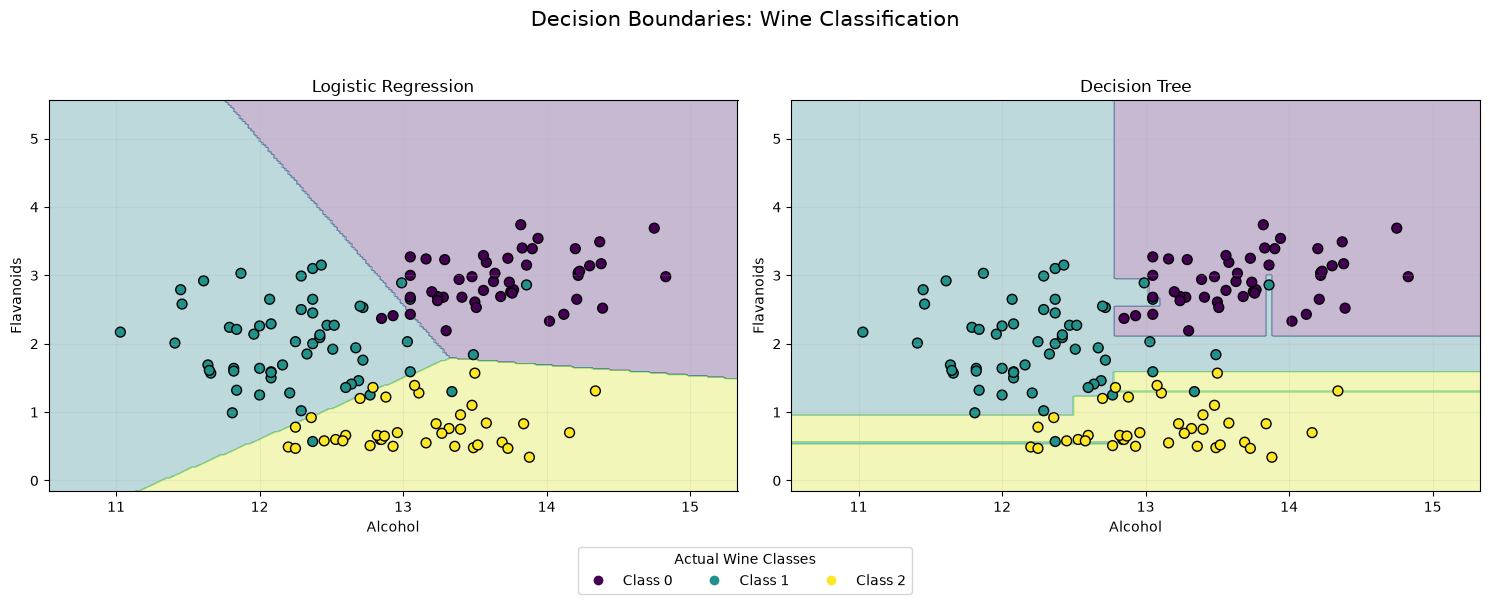

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# Define the plotting area using the feature ranges
x_min, x_max = X_2d["alcohol"].min() - 0.5, X_2d["alcohol"].max() + 0.5
y_min, y_max = X_2d["flavanoids"].min() - 0.5, X_2d["flavanoids"].max() + 0.5

# Create a grid of points
xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.02),
    np.arange(y_min, y_max, 0.02)
)

# Combine grid coordinates into feature pairs
grid = np.c_[xx.ravel(), yy.ravel()]

# Logistic Regression predictions
grid_scaled = scaler_2d.transform(grid)
Z_logistic = logistic_2d.predict(grid_scaled)
Z_logistic = Z_logistic.reshape(xx.shape)

# Decision Tree predictions
Z_tree = tree_2d.predict(grid)
Z_tree = Z_tree.reshape(xx.shape)

# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

models = [
    ("Logistic Regression", Z_logistic),
    ("Decision Tree", Z_tree)
]

for ax, (title, Z) in zip(axes, models):

    # Draw predicted regions
    ax.contourf(
        xx,
        yy,
        Z,
        alpha=0.3,
        cmap="viridis"
    )

    # Draw actual training samples
    scatter = ax.scatter(
        X_train_2d["alcohol"],
        X_train_2d["flavanoids"],
        c=y_train_2d,
        cmap="viridis",
        edgecolors="black",
        s=50
    )

    ax.set_title(title)
    ax.set_xlabel("Alcohol")
    ax.set_ylabel("Flavanoids")

    ax.grid(alpha=0.2)

# Add a shared legend
handles, labels = scatter.legend_elements()

fig.legend(
    handles,
    ["Class 0", "Class 1", "Class 2"],
    title="Actual Wine Classes",
    loc="lower center",
    ncol=3
)

plt.suptitle("Decision Boundaries: Wine Classification", fontsize=15)
plt.tight_layout(rect=[0, 0.08, 1, 0.95])
plt.show()

In [19]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline

# Define 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Logistic Regression pipeline
logistic_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Cross-validation for Logistic Regression
logistic_cv_scores = cross_val_score(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

# Cross-validation for Decision Tree
tree_cv_scores = cross_val_score(
    tree_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

# Display results
print("LOGISTIC REGRESSION")
print("Fold scores:", logistic_cv_scores.round(4))
print("Mean accuracy:", logistic_cv_scores.mean().round(4))
print("Standard deviation:", logistic_cv_scores.std().round(4))

print("\nDECISION TREE")
print("Fold scores:", tree_cv_scores.round(4))
print("Mean accuracy:", tree_cv_scores.mean().round(4))
print("Standard deviation:", tree_cv_scores.std().round(4))

LOGISTIC REGRESSION
Fold scores: [0.931  1.     1.     1.     0.9643]
Mean accuracy: 0.9791
Standard deviation: 0.0277

DECISION TREE
Fold scores: [0.7931 0.8966 0.9286 0.9643 0.9286]
Mean accuracy: 0.9022
Standard deviation: 0.0586


In [20]:
# Save model comparison
comparison.to_csv(
    "../results/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [21]:
# Create cross-validation results DataFrame
cv_results = pd.DataFrame({
    "Fold": [1, 2, 3, 4, 5],
    "Logistic Regression": logistic_cv_scores,
    "Decision Tree": tree_cv_scores
})

# Add mean and standard deviation
print(cv_results.round(4))

cv_results.to_csv(
    "../results/cross_validation_results.csv",
    index=False
)

print("\nCross-validation results saved successfully!")

   Fold  Logistic Regression  Decision Tree
0     1               0.9310         0.7931
1     2               1.0000         0.8966
2     3               1.0000         0.9286
3     4               1.0000         0.9643
4     5               0.9643         0.9286

Cross-validation results saved successfully!
